# Pharmaceutical Operations Intelligence System

## Integrated SQL, extensive data cleaning, exploratory data analysis, and predictive models

This notebook combines the production and maintenance datasets, checks and treats missing values, explores the data with tables and visualisations, and builds simple-to-follow machine-learning models. It includes classification, regression, anomaly detection, maintenance-status analysis, and production-volume forecasting.

In [85]:
# Imports
import os, sys, sqlite3, warnings, json, math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (classification_report, confusion_matrix, precision_score,
                             recall_score, f1_score, roc_auc_score, average_precision_score,
                             mean_absolute_error, mean_squared_error, r2_score)
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, GradientBoostingClassifier, IsolationForest
from sklearn.neural_network import MLPClassifier
from sklearn.decomposition import PCA

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
plt.rcParams['figure.figsize'] = (10, 5)


## 2. Load source files and inspect structure

In [87]:
production = pd.read_csv('LAL_Batch_Manufacturing_Production.csv')
maintenance = pd.read_csv('LAL_Equipment_Maintenance_Records.csv')

print('Production shape:', production.shape)
print('Maintenance shape:', maintenance.shape)
print('Production columns:', production.columns.tolist())
print('Maintenance columns:', maintenance.columns.tolist())
display(production.head())
display(maintenance.head())

Production shape: (60000, 30)
Maintenance shape: (60000, 16)
Production columns: ['batch_id', 'drug_name', 'dosage_form', 'manufacturing_section', 'production_start', 'batch_size', 'batch_size_unit', 'equipment_id', 'equipment_name', 'equipment_age_days', 'maintenance_days_ago', 'upstream_equipment_id', 'downstream_equipment_id', 'ahu_id', 'operator_id', 'operator_experience_years', 'temp_avg', 'temp_variance', 'pressure_avg', 'pressure_variance', 'humidity_avg', 'production_hours', 'raw_material_quality', 'target_yield', 'actual_yield', 'assay_result_purity', 'impurity_level', 'dissolution_time_min', 'batch_passed', 'rejection_reason']
Maintenance columns: ['batch_id', 'equipment_id', 'equipment_name', 'manufacturing_section', 'production_date', 'equipment_age_days', 'maintenance_days_ago', 'maintenance_status', 'upstream_equipment_id', 'downstream_equipment_id', 'operator_experience_years', 'batch_size', 'batch_size_unit', 'production_hours', 'batch_passed', 'rejection_reason']


,batch_id,drug_name,dosage_form,manufacturing_section,production_start,batch_size,batch_size_unit,equipment_id,equipment_name,equipment_age_days,...,humidity_avg,production_hours,raw_material_quality,target_yield,actual_yield,assay_result_purity,impurity_level,dissolution_time_min,batch_passed,rejection_reason
0,TOT-07-0001,Totomol,Tablet,Oral Solids,2007-01-02,250,kg,LAL/TAB/006,35 STN Compression Machine,1695,...,44.0,26.7,99.6,95.0,99.79,100.69,0.098,17.26,1,NaN
1,ACM-07-0001,Acemol,Tablet,Oral Solids,2007-01-03,250,kg,LAL/TAB/006,35 STN Compression Machine,1696,...,47.1,21.4,99.8,95.0,99.21,99.55,0.104,16.67,1,NaN
2,ACM-07-0002,Acemol,Tablet,Oral Solids,2007-01-03,200,kg,LAL/TAB/006,35 STN Compression Machine,1696,...,48.7,19.6,99.6,95.0,98.62,100.18,0.066,15.06,1,NaN
3,ALS-07-0001,Altoa Suspension,Oral Suspension,Oral Liquids,2007-01-03,500,L,LAL/LIQ/003,Liquids Mfg Tank (500 L),1633,...,40.7,7.2,99.0,98.0,98.86,102.38,0.161,NaN,1,NaN
4,ALS-07-0002,Altoa Suspension,Oral Suspension,Oral Liquids,2007-01-03,300,L,LAL/LIQ/003,Liquids Mfg Tank (500 L),1633,...,57.9,6.7,99.8,98.0,98.80,99.51,0.282,NaN,1,NaN


,batch_id,equipment_id,equipment_name,manufacturing_section,production_date,equipment_age_days,maintenance_days_ago,maintenance_status,upstream_equipment_id,downstream_equipment_id,operator_experience_years,batch_size,batch_size_unit,production_hours,batch_passed,rejection_reason
0,TOT-07-0001,LAL/TAB/006,35 STN Compression Machine,Oral Solids,02/01/2007,1695,78,Current,LAL/TAB/012,LAL/TAB/008,3,250,kg,26.7,1,NaN
1,ACM-07-0001,LAL/TAB/006,35 STN Compression Machine,Oral Solids,03/01/2007,1696,79,Current,LAL/TAB/012,LAL/TAB/008,8,250,kg,21.4,1,NaN
2,ACM-07-0002,LAL/TAB/006,35 STN Compression Machine,Oral Solids,03/01/2007,1696,79,Current,LAL/TAB/012,LAL/TAB/008,2,200,kg,19.6,1,NaN
3,ALS-07-0001,LAL/LIQ/003,Liquids Mfg Tank (500 L),Oral Liquids,03/01/2007,1633,79,Current,LAL/LIQ/014,LAL/LIQ/008,10,500,L,7.2,1,NaN
4,ALS-07-0002,LAL/LIQ/003,Liquids Mfg Tank (500 L),Oral Liquids,03/01/2007,1633,79,Current,LAL/LIQ/014,LAL/LIQ/008,4,300,L,6.7,1,NaN


## 3. Integrate datasets using SQL

In [89]:
# Join production and maintenance data using SQL
conn = sqlite3.connect(":memory:")

production.to_sql("production", conn, index=False, if_exists="replace")
maintenance.to_sql("maintenance", conn, index=False, if_exists="replace")

# Join the two tables
combined_data = pd.read_sql_query("""
    SELECT p.*,
           m.maintenance_status,
           m.production_date AS maintenance_production_date
    FROM production p
    LEFT JOIN maintenance m
    ON p.batch_id = m.batch_id
""", conn)

# Display the joined data
display(combined_data.head())

# Check the shape
print("Joined data shape:", combined_data.shape)

# Close the connection
conn.close()

,batch_id,drug_name,dosage_form,manufacturing_section,production_start,batch_size,batch_size_unit,equipment_id,equipment_name,equipment_age_days,...,raw_material_quality,target_yield,actual_yield,assay_result_purity,impurity_level,dissolution_time_min,batch_passed,rejection_reason,maintenance_status,maintenance_production_date
0,TOT-07-0001,Totomol,Tablet,Oral Solids,2007-01-02,250,kg,LAL/TAB/006,35 STN Compression Machine,1695,...,99.6,95.0,99.79,100.69,0.098,17.26,1,None,Current,02/01/2007
1,ACM-07-0001,Acemol,Tablet,Oral Solids,2007-01-03,250,kg,LAL/TAB/006,35 STN Compression Machine,1696,...,99.8,95.0,99.21,99.55,0.104,16.67,1,None,Current,03/01/2007
2,ACM-07-0002,Acemol,Tablet,Oral Solids,2007-01-03,200,kg,LAL/TAB/006,35 STN Compression Machine,1696,...,99.6,95.0,98.62,100.18,0.066,15.06,1,None,Current,03/01/2007
3,ALS-07-0001,Altoa Suspension,Oral Suspension,Oral Liquids,2007-01-03,500,L,LAL/LIQ/003,Liquids Mfg Tank (500 L),1633,...,99.0,98.0,98.86,102.38,0.161,NaN,1,None,Current,03/01/2007
4,ALS-07-0002,Altoa Suspension,Oral Suspension,Oral Liquids,2007-01-03,300,L,LAL/LIQ/003,Liquids Mfg Tank (500 L),1633,...,99.8,98.0,98.80,99.51,0.282,NaN,1,None,Current,03/01/2007


Joined data shape: (60000, 32)


In [90]:
# Number of rows and columns
print("Data shape:", combined_data.shape)

# Display column names
print(combined_data.columns.tolist())

# Check data types and missing values
combined_data.info()

# summary
combined_data.describe()

# Count duplicate rows
print("Duplicate rows:", combined_data.duplicated().sum())

# Display the first 5 rows
display(combined_data.head())


Data shape: (60000, 32)
['batch_id', 'drug_name', 'dosage_form', 'manufacturing_section', 'production_start', 'batch_size', 'batch_size_unit', 'equipment_id', 'equipment_name', 'equipment_age_days', 'maintenance_days_ago', 'upstream_equipment_id', 'downstream_equipment_id', 'ahu_id', 'operator_id', 'operator_experience_years', 'temp_avg', 'temp_variance', 'pressure_avg', 'pressure_variance', 'humidity_avg', 'production_hours', 'raw_material_quality', 'target_yield', 'actual_yield', 'assay_result_purity', 'impurity_level', 'dissolution_time_min', 'batch_passed', 'rejection_reason', 'maintenance_status', 'maintenance_production_date']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60000 entries, 0 to 59999
Data columns (total 32 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   batch_id                     60000 non-null  object 
 1   drug_name                    60000 non-null  object 
 2   dosage_form  

,batch_id,drug_name,dosage_form,manufacturing_section,production_start,batch_size,batch_size_unit,equipment_id,equipment_name,equipment_age_days,...,raw_material_quality,target_yield,actual_yield,assay_result_purity,impurity_level,dissolution_time_min,batch_passed,rejection_reason,maintenance_status,maintenance_production_date
0,TOT-07-0001,Totomol,Tablet,Oral Solids,2007-01-02,250,kg,LAL/TAB/006,35 STN Compression Machine,1695,...,99.6,95.0,99.79,100.69,0.098,17.26,1,None,Current,02/01/2007
1,ACM-07-0001,Acemol,Tablet,Oral Solids,2007-01-03,250,kg,LAL/TAB/006,35 STN Compression Machine,1696,...,99.8,95.0,99.21,99.55,0.104,16.67,1,None,Current,03/01/2007
2,ACM-07-0002,Acemol,Tablet,Oral Solids,2007-01-03,200,kg,LAL/TAB/006,35 STN Compression Machine,1696,...,99.6,95.0,98.62,100.18,0.066,15.06,1,None,Current,03/01/2007
3,ALS-07-0001,Altoa Suspension,Oral Suspension,Oral Liquids,2007-01-03,500,L,LAL/LIQ/003,Liquids Mfg Tank (500 L),1633,...,99.0,98.0,98.86,102.38,0.161,NaN,1,None,Current,03/01/2007
4,ALS-07-0002,Altoa Suspension,Oral Suspension,Oral Liquids,2007-01-03,300,L,LAL/LIQ/003,Liquids Mfg Tank (500 L),1633,...,99.8,98.0,98.80,99.51,0.282,NaN,1,None,Current,03/01/2007


## 4. Data cleaning and missing-value treatment


In [92]:
# Check the date column
print(combined_data["production_start"].head())

# Convert the date to datetime format
combined_data["production_start"] = pd.to_datetime(
    combined_data["production_start"], errors="coerce"
)

# Check the earliest and latest dates
print("Earliest date:", combined_data["production_start"].min())
print("Latest date:", combined_data["production_start"].max())

# Count missing dates
print("Missing dates:", combined_data["production_start"].isnull().sum())

# Extract year and month
combined_data["year"] = combined_data["production_start"].dt.year
combined_data["month"] = combined_data["production_start"].dt.month

# Display the cleaned dates
combined_data[["production_start", "year", "month"]].head()

0    2007-01-02
1    2007-01-03
2    2007-01-03
3    2007-01-03
4    2007-01-03
Name: production_start, dtype: object
Earliest date: 2007-01-02 00:00:00
Latest date: 2026-10-09 00:00:00
Missing dates: 0


,production_start,year,month
0,2007-01-02,2007,1
1,2007-01-03,2007,1
2,2007-01-03,2007,1
3,2007-01-03,2007,1
4,2007-01-03,2007,1


**Handle missing values carefully**

Avoid filling every missing value with the same method. For example, a missing dissolution time may mean the test was not applicable, while a missing quality test result should remain missing.

In [94]:
# Check missing values before cleaning
print(combined_data.isnull().sum())

# Remove duplicate rows
combined_data = combined_data.drop_duplicates()

# Fill missing numeric values with the median
numeric_columns = combined_data.select_dtypes(include="number").columns

for col in numeric_columns:
    combined_data[col] = combined_data[col].fillna(
        combined_data[col].mean()
    )

# Fill missing text values with the most common value
text_columns = combined_data.select_dtypes(include="object").columns

for col in text_columns:
    if combined_data[col].isnull().any():
        combined_data[col] = combined_data[col].fillna(
            combined_data[col].mode()[0]
        )

# # Standardize identifier names
# id_columns = [
#     "batch_id", "equipment_id", "operator_id",
#     "upstream_equipment_id", "downstream_equipment_id", "ahu_id"
# ]

# for col in id_columns:
#     if col in combined_data.columns:
#         combined_data[col] = combined_data[col].str.upper()


# 11.Identify outliers in numeric columns
# numeric_columns_1 = ()

numeric_columns = combined_data.select_dtypes(include="int").columns

for col in numeric_columns:
    Q1 = combined_data[col].quantile(0.25)
    Q3 = combined_data[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = combined_data[
        (combined_data[col] < lower_limit) |
        (combined_data[col] > upper_limit)
    ]

    if len(outliers) > 0:
        print(col, "- Outliers found:", len(outliers))

print("Outlier checking completed.")

# Check missing values after cleaning
print("Missing values after cleaning:")
print(combined_data.isnull().sum())

batch_id                           0
drug_name                          0
dosage_form                        0
manufacturing_section              0
production_start                   0
batch_size                         0
batch_size_unit                    0
equipment_id                       0
equipment_name                     0
equipment_age_days                 0
maintenance_days_ago               0
upstream_equipment_id              0
downstream_equipment_id            0
ahu_id                             0
operator_id                        0
operator_experience_years          0
temp_avg                         442
temp_variance                    795
pressure_avg                     587
pressure_variance                715
humidity_avg                     862
production_hours                 289
raw_material_quality             682
target_yield                       0
actual_yield                     230
assay_result_purity                0
impurity_level                   300
d

**Check whether the join created duplicate batch IDs**

Because you combined production and maintenance data, check that each batch appears only once.

In [96]:
# Count duplicate batch IDs
print("Duplicate batch IDs:", combined_data["batch_id"].duplicated().sum())

# Display duplicated batch records, if any
display(
    combined_data[
        combined_data["batch_id"].duplicated(keep=False)
    ].head(10)
)

Duplicate batch IDs: 0


,batch_id,drug_name,dosage_form,manufacturing_section,production_start,batch_size,batch_size_unit,equipment_id,equipment_name,equipment_age_days,...,actual_yield,assay_result_purity,impurity_level,dissolution_time_min,batch_passed,rejection_reason,maintenance_status,maintenance_production_date,year,month


# Final data quality check

summary statistics**
query colums
missing values
fix data types
standadise data types
outliuers
fix errors eg check negative values
consistencies accross columns
clean text data


In [99]:
print("Final data shape:", combined_data.shape)
print("Total missing values:", combined_data.isnull().sum().sum())
print("Duplicate rows:", combined_data.duplicated().sum())

display(combined_data.head())

Final data shape: (60000, 34)
Total missing values: 0
Duplicate rows: 0


,batch_id,drug_name,dosage_form,manufacturing_section,production_start,batch_size,batch_size_unit,equipment_id,equipment_name,equipment_age_days,...,actual_yield,assay_result_purity,impurity_level,dissolution_time_min,batch_passed,rejection_reason,maintenance_status,maintenance_production_date,year,month
0,TOT-07-0001,Totomol,Tablet,Oral Solids,2007-01-02,250,kg,LAL/TAB/006,35 STN Compression Machine,1695,...,99.79,100.69,0.098,17.260000,1,Assay out of specification,Current,02/01/2007,2007,1
1,ACM-07-0001,Acemol,Tablet,Oral Solids,2007-01-03,250,kg,LAL/TAB/006,35 STN Compression Machine,1696,...,99.21,99.55,0.104,16.670000,1,Assay out of specification,Current,03/01/2007,2007,1
2,ACM-07-0002,Acemol,Tablet,Oral Solids,2007-01-03,200,kg,LAL/TAB/006,35 STN Compression Machine,1696,...,98.62,100.18,0.066,15.060000,1,Assay out of specification,Current,03/01/2007,2007,1
3,ALS-07-0001,Altoa Suspension,Oral Suspension,Oral Liquids,2007-01-03,500,L,LAL/LIQ/003,Liquids Mfg Tank (500 L),1633,...,98.86,102.38,0.161,15.320502,1,Assay out of specification,Current,03/01/2007,2007,1
4,ALS-07-0002,Altoa Suspension,Oral Suspension,Oral Liquids,2007-01-03,300,L,LAL/LIQ/003,Liquids Mfg Tank (500 L),1633,...,98.80,99.51,0.282,15.320502,1,Assay out of specification,Current,03/01/2007,2007,1


# 5. Exploratory Data Analysis (EDA)

Analyze the cleaned combined_data dataset to understand production performance and equipment maintenance.
- Visualize the distribution of actual_yield.
- Correlation heatmap
- Compare temperature and pressure with actual yield.
- Compare passed and failed batches.
- Analyze batch failures by production date and other relevant process variables.
- Production over time
- Examine maintenance status and its relationship with batch outcomes.
- Summarize key findings and business implications.

Output: EDA charts and a short findings report.

**a) Distribution of actual yield**

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


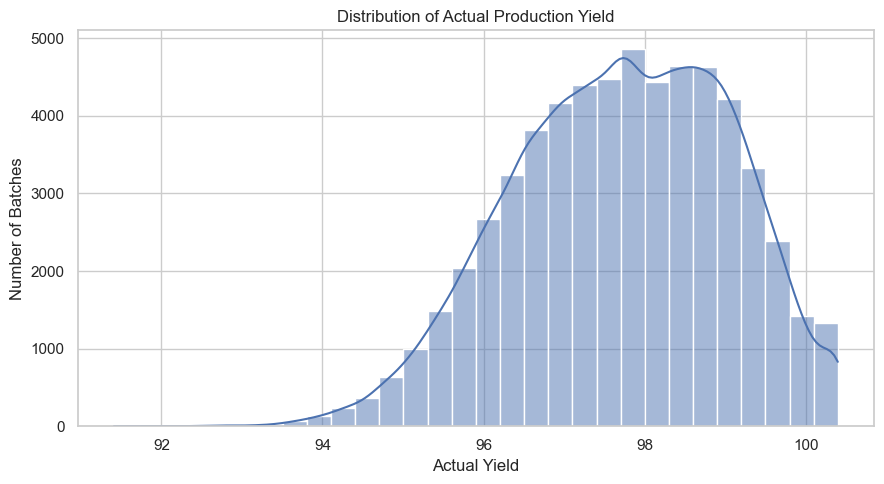

In [102]:

sns.set_theme(style="whitegrid")

plt.figure(figsize=(9, 5))

sns.histplot(
    data=combined_data,
    x="actual_yield",
    bins=30,
    kde=True
)

plt.title("Distribution of Actual Production Yield")
plt.xlabel("Actual Yield")
plt.ylabel("Number of Batches")
plt.tight_layout()
plt.show()

**b) Correlation heatmap**

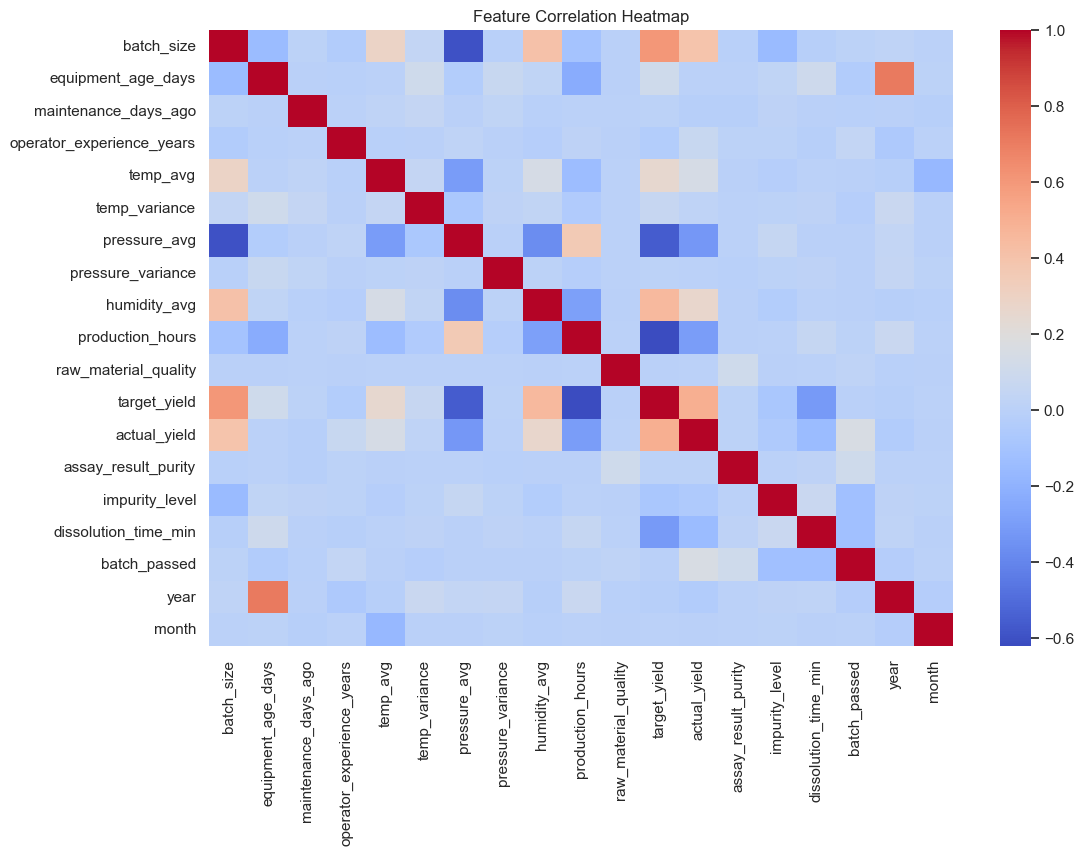

In [104]:

plt.figure(figsize=(12, 8))

sns.heatmap(
    combined_data.select_dtypes(include="number").corr(),
    cmap="coolwarm",
    annot=False
)

plt.title("Feature Correlation Heatmap")
plt.show()

**c) Group temperatures into ranges**

/opt/anaconda3/lib/python3.11/site-packages/seaborn/categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)


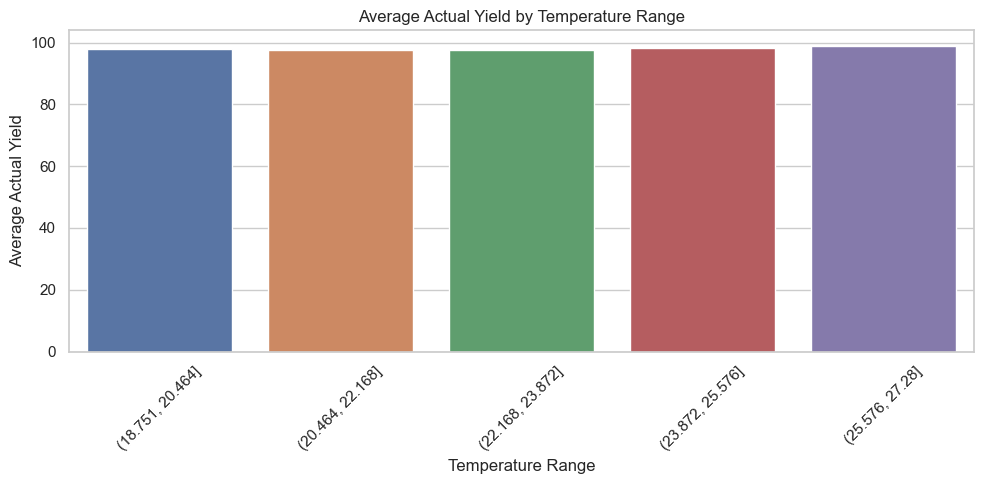

In [106]:
combined_data["temp_range"] = pd.cut(
    combined_data["temp_avg"],
    bins=5
)

# Create the bar plot
sns.barplot(
    data=combined_data,
    x="temp_range",
    y="actual_yield",
    errorbar=None
)

plt.title("Average Actual Yield by Temperature Range")
plt.xlabel("Temperature Range")
plt.ylabel("Average Actual Yield")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**d) Actual yield by batch pass status**

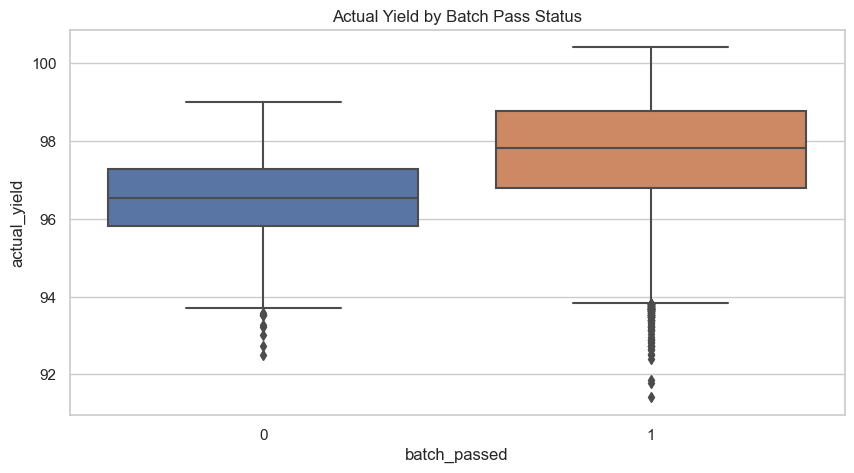

In [108]:

sns.boxplot(
    data=combined_data,
    x="batch_passed",
    y="actual_yield"
)

plt.title("Actual Yield by Batch Pass Status")
plt.show()

**e) Batch quality outcomes**

batch_passed
1    58125
0     1875
Name: count, dtype: int64


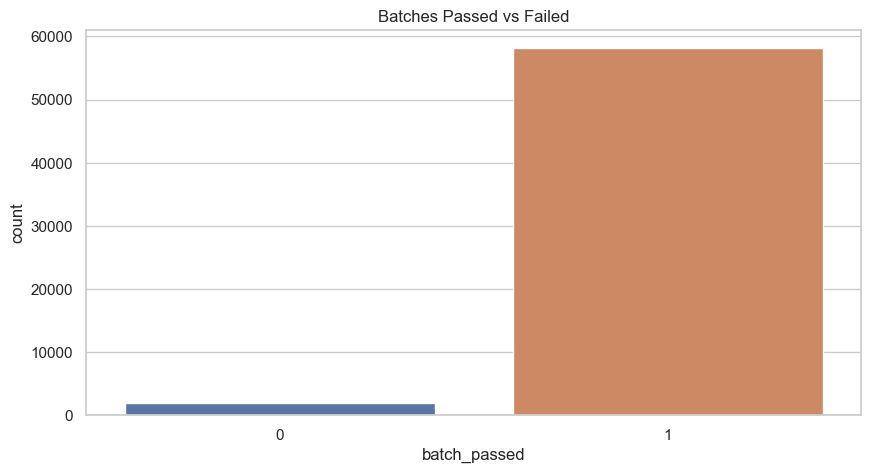

In [110]:
# Count batches that passed and failed
print(combined_data["batch_passed"].value_counts())

# Plot the results
sns.countplot(data=combined_data, x="batch_passed")

plt.title("Batches Passed vs Failed")
plt.show()

**f) Production over time**

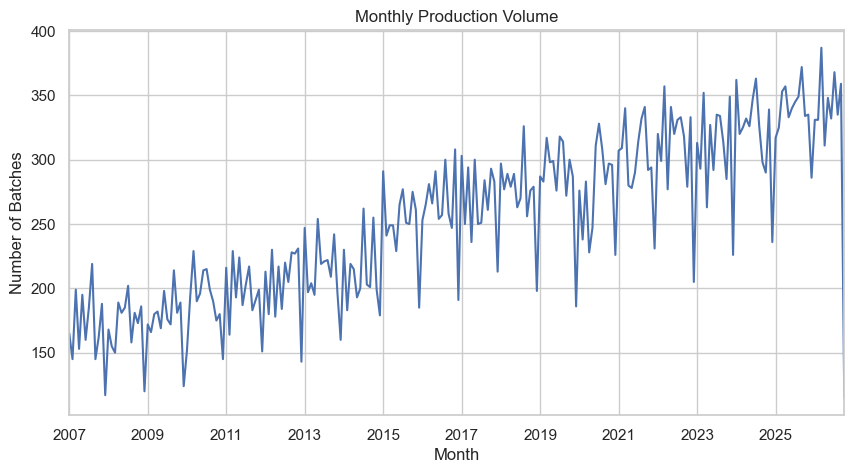

In [112]:

combined_data["production_start"] = pd.to_datetime(
    combined_data["production_start"], errors="coerce"
)

monthly_batches = combined_data.dropna(
    subset=["production_start"]
).set_index("production_start").resample("M")["batch_id"].count()

monthly_batches.plot(figsize=(10, 5))

plt.title("Monthly Production Volume")
plt.xlabel("Month")
plt.ylabel("Number of Batches")
plt.show()

**g). Examine maintenance status and batch outcomes**

This section compares batch pass/fail outcomes across maintenance categories, such as Current, Due Soon, and Critical.

batch_outcome,Failed,Passed
maintenance_status,,
Critical,33,443
Current,1687,52553
Due Soon,155,5129


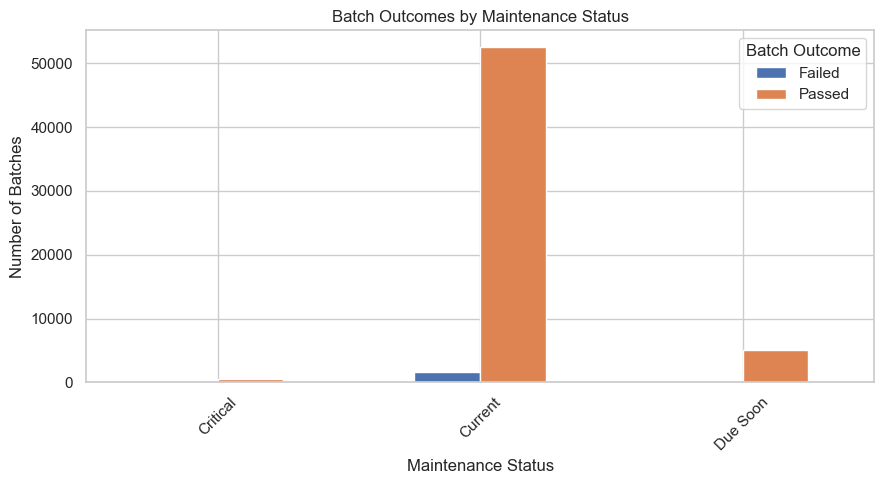

In [114]:
# Create a copy of the combined dataset
maintenance_data = combined_data.copy()

# Create batch outcome labels
maintenance_data["batch_outcome"] = maintenance_data["batch_passed"].apply(
    lambda x: "Passed" if str(x).strip().lower() in ["1", "1.0", "true", "pass", "passed"]
    else "Failed" if str(x).strip().lower() in ["0", "0.0", "false", "fail", "failed"]
    else "Unknown"
)

# Handle missing maintenance status
maintenance_data["maintenance_status"] = (
    maintenance_data["maintenance_status"].fillna("Unknown")
)

# Count outcomes for each maintenance status
maintenance_counts = pd.crosstab(
    maintenance_data["maintenance_status"],
    maintenance_data["batch_outcome"]
)

display(maintenance_counts)

# Visualize batch outcomes by maintenance status
maintenance_counts.plot(kind="bar", figsize=(9, 5))

plt.title("Batch Outcomes by Maintenance Status")
plt.xlabel("Maintenance Status")
plt.ylabel("Number of Batches")
plt.xticks(rotation=45)
plt.legend(title="Batch Outcome")
plt.tight_layout()
plt.show()


**h).EDA findings report**

In [116]:

# Create batch outcome labels in combined_data
combined_data["batch_outcome"] = combined_data["batch_passed"].apply(
    lambda x: "Passed" if str(x).strip().lower() in ["1", "1.0", "true", "pass", "passed"]
    else "Failed" if str(x).strip().lower() in ["0", "0.0", "false", "fail", "failed"]
    else "Unknown"
)

# Check the results
print(combined_data["batch_outcome"].value_counts(dropna=False))



print("=" * 55)
print("PHARMACEUTICAL OPERATIONS INTELLIGENCE SYSTEM")
print("EXPLORATORY DATA ANALYSIS FINDINGS")
print("=" * 55)

# 1. Actual yield summary
if "actual_yield" in combined_data.columns:
    print("\n1. PRODUCTION YIELD")
    print("Average yield:", round(combined_data["actual_yield"].mean(), 2))
    print("Median yield:", round(combined_data["actual_yield"].median(), 2))
    print("Minimum yield:", round(combined_data["actual_yield"].min(), 2))
    print("Maximum yield:", round(combined_data["actual_yield"].max(), 2))

# 2. Batch outcomes
print("\n2. BATCH QUALITY")
print(combined_data["batch_outcome"].value_counts(dropna=False))

known_outcomes = combined_data["batch_outcome"].dropna()
if len(known_outcomes) > 0:
    failure_rate = (known_outcomes == "Failed").mean() * 100
    print(f"Overall batch failure rate: {failure_rate:.2f}%")

# 3. Correlation with actual yield
print("\n3. FACTORS ASSOCIATED WITH YIELD")

if "actual_yield" in combined_data.columns:
    numeric_data = combined_data.select_dtypes(include="number")
    correlations = numeric_data.corr()["actual_yield"].drop(
        labels=["actual_yield"], errors="ignore"
    ).dropna()

    if len(correlations) > 0:
        print("Strongest positive correlations:")
        print(correlations.sort_values(ascending=False).head(3))

        print("\nStrongest negative correlations:")
        print(correlations.sort_values().head(3))
    else:
        print("Insufficient numerical data to calculate correlations.")

# 4. Maintenance
print("\n4. MAINTENANCE STATUS")

if "maintenance_status" in combined_data.columns:
    print(combined_data["maintenance_status"].value_counts(dropna=False))

    maintenance_summary = pd.crosstab(
        maintenance_data["maintenance_status"],
        maintenance_data["batch_outcome"],
        normalize="index"
    ) * 100

    if "Failed" in maintenance_summary.columns:
        print("\nFailure rate by maintenance status (%):")
        print(maintenance_summary["Failed"].round(2))

print("\nEDA summary completed.")

batch_outcome
Passed    58125
Failed     1875
Name: count, dtype: int64
PHARMACEUTICAL OPERATIONS INTELLIGENCE SYSTEM
EXPLORATORY DATA ANALYSIS FINDINGS

1. PRODUCTION YIELD
Average yield: 97.71
Median yield: 97.77
Minimum yield: 91.41
Maximum yield: 100.4

2. BATCH QUALITY
batch_outcome
Passed    58125
Failed     1875
Name: count, dtype: int64
Overall batch failure rate: 3.12%

3. FACTORS ASSOCIATED WITH YIELD
Strongest positive correlations:
target_yield    0.504756
batch_size      0.394001
humidity_avg    0.261623
Name: actual_yield, dtype: float64

Strongest negative correlations:
pressure_avg           -0.326155
production_hours       -0.301432
dissolution_time_min   -0.147206
Name: actual_yield, dtype: float64

4. MAINTENANCE STATUS
maintenance_status
Current     54240
Due Soon     5284
Critical      476
Name: count, dtype: int64

Failure rate by maintenance status (%):
maintenance_status
Critical    6.93
Current     3.11
Due Soon    2.93
Name: Failed, dtype: float64

EDA summary

# 6. Feature Engineering

Create useful variables from the existing data.
- Extract year, month, and other useful date features.
- Create indicators for missing measurements where relevant.
- Encode categorical variables.
- Select relevant production and maintenance features.
- Check for data leakage before modeling.


In [118]:
# code here

# 7. Define the Prediction Problems

- Batch quality prediction: predict whether batch_passed will be 0 or 1.
- Yield prediction: estimate actual_yield using information available before the outcome is known.
For preventive maintenance, first confirm whether the maintenance data contains actual failure events, dates, and downtime.



In [120]:
# code here

# 8. Prepare Training and Testing Data
- Separate the input features (X) from the target (y).
- Split data into training and testing sets.
- Prefer a time-based split when predicting future production outcomes.
- Scale numerical features where required.
- Handle the imbalance between passed and failed batches.


In [122]:
# code here

# 9. Build and Compare Predictive Models

Start with simple models before more complex ones.

| Problem | Models to Try |
|---|---|
| Batch pass/fail | Logistic Regression, Decision Tree, Random Forest, Neural Network |
| Yield prediction | Linear Regression, Random Forest Regressor, Neural Network |
| Equipment failure | Logistic Regression or Random Forest, if failure labels are available |



In [124]:
# code here

# 10. Evaluate the Models

For batch classification, calculate precision, recall, F1-score, and a confusion matrix. Pay special attention to identifying failed batches.

For yield prediction, calculate MAE, RMSE, and \(R^2\).

Compare the models against baseline performance and check whether the results are useful operationally.



In [126]:
# code here

# 11. Develop the Inventory, Quality, and Maintenance Modules

Your proposal also requires demand forecasting, stock-out and expiry risk analysis, quality compliance monitoring, and equipment reliability analysis. 

Your current production and maintenance datasets support parts of the quality and maintenance work. To complete the full proposal, you will also need suitable inventory and sales records, including transaction dates, quantities sold, stock levels, costs, and expiry information where available.



In [128]:
# code here

# 12. Build the Dashboard

Use Streamlit or Power BI to present:
- Production yield and batch pass/fail rates.
- Predicted batch failure risks.
- Inventory forecasts and expiry alerts, once inventory data is available.
- Equipment condition and maintenance priorities.
- Recommended actions for managers.



# 13. Final Validation and Presentation
- Test the system on unseen data.
- Back-test recommendations against historical outcomes.
- Document assumptions, limitations, and results.
- Prepare the final report, notebook, dashboard, and presentation.
